# ЛАБОРАТОРНА РОБОТА № 4

## Візуальний аналіз даних та часові ряди — аналіз у двох середовищах

**Курс:** СК26 «Інтелектуальний аналіз та візуалізація даних»
**Кафедра систем штучного інтелекту, Національний університет «Львівська політехніка»**
**Оцінювання:** 4 бали

---

## Визначення варіанта

Заповніть три поля в клітинці нижче й виконайте обидві службові клітинки —
номер варіанта, ринок і товар визначаться автоматично.

In [94]:
# ── Заповніть три поля ──────────────────────────────────────────
SURNAME_NAME = 'Кшик Олена'      # прізвище та ім'я
GROUP        = 'ШІ-34'      # шифр групи, наприклад СШІ-31
NUMBER       = 9       # ваш номер за списком групи (1–30)

assert SURNAME_NAME.strip(), 'Впишіть прізвище та ім\'я'
assert GROUP.strip(),        'Впишіть групу'
assert isinstance(NUMBER, int) and 1 <= NUMBER <= 30, 'Номер має бути цілим від 1 до 30'
print('Дані прийнято:', SURNAME_NAME, '|', GROUP, '| номер', NUMBER)

Дані прийнято: Кшик Олена | ШІ-34 | номер 9


In [95]:
# ── Службова клітинка: визначення варіанта. Змінювати не потрібно ──
import json

VARIANTS = json.load(open('lr4_variants_student.json', encoding='utf-8'))
V = VARIANTS[NUMBER - 1]

MARKET, GOOD, GOOD_UA = V['ринок'], V['товар'], V['товар_укр']

print('=' * 72)
print(f'ВАРІАНТ {V["варіант"]}   ·   {SURNAME_NAME}   ·   {GROUP}')
print('=' * 72)
print()
print(f'   Ринок:  {MARKET}')
print(f'   Товар:  {GOOD_UA}   (у наборі даних: {GOOD})')
print()
print('Далі в роботі користуйтеся змінними MARKET і GOOD —')
print('тоді весь код автоматично працюватиме саме з вашим рядом.')
print()
print('Період: 03.2014 – 12.2017 · очікувана довжина ряду: 46 місяців')
print('Фолдів ретроспективної перевірки: 7 · горизонт: 3 місяці · ARIMA(1, 1, 1)')

ВАРІАНТ 9   ·   Кшик Олена   ·   ШІ-34

   Ринок:  Rivne
   Товар:  ковбаса   (у наборі даних: Meat (mixed, sausage) - Retail)

Далі в роботі користуйтеся змінними MARKET і GOOD —
тоді весь код автоматично працюватиме саме з вашим рядом.

Період: 03.2014 – 12.2017 · очікувана довжина ряду: 46 місяців
Фолдів ретроспективної перевірки: 7 · горизонт: 3 місяці · ARIMA(1, 1, 1)


> ⚠️ Якщо ці дві клітинки не виконано, усі подальші завдання не мають сенсу:
> перевіряти роботу будуть **за вашим варіантом**, а не за тим рядом, який ви оберете самі.

| | |
|---|---|
| **Дата здачі** | |
| **Підпис** | |

---
## Мета роботи

Виконати повний цикл аналізу одного часового ряду **у двох середовищах** — у Python та в Orange —
і пояснити, чому однаково названі метрики в них дають різні числа.

## Вихідні дані

| Файл | Зміст |
|---|---|
| `ціни_україна_2014_2017.csv` | Роздрібні ціни на 25 товарів по 28 ринках України, щомісяця, 03.2014 – 12.2017 |
| `lr4_variants_student.json` | Розподіл варіантів (зчитується автоматично) |
| `ЛР4_помилковий_аналіз.ipynb` | Звіт колеги, який треба відрецензувати (завдання 8) |

Це той самий набір, з яким ми працювали на лекції 4. **Національне середнє в завданнях не використовується** —
ваш ряд це конкретний обласний ринок.

## Що здавати

1. **`ЛР4_Прізвище_Варіант.ipynb`** — цей зошит із вашим кодом, графіками та письмовими висновками.
2. **`ряд_для_orange.csv`** — експортований ряд (завдання 9).
3. **`потік_orange.ows`** — збережений потік Orange.
4. **Знімки екрана** з Orange для завдань 10–13 — вставте їх у зошит або додайте окремими файлами.

## Правила

* **Код пишете самостійно** — у цьому зошиті навмисно немає заготовок.
* **Користуватися штучним інтелектом дозволено**, але ви зобов'язані заповнити декларацію в кінці зошита.
* **Кожне число має супроводжуватися висновком словами.** Робота, у якій є графіки й таблиці,
  але немає письмових відповідей на поставлені питання, оцінюється як невиконана.
* Усі обчислення мають бути **відтворюваними**: зошит має виконуватися від початку до кінця
  командою *Restart & Run All* без помилок.

---
# ЧАСТИНА 1. Аналіз засобами Python

*Виконується аудиторно.*

## Завдання 1. Підготовка ряду

Витягніть із набору ряд свого варіанта — скористайтеся змінними `MARKET` і `GOOD`,
які визначилися у службовій клітинці, — і приведіть його до **повної місячної сітки**
з березня 2014 по грудень 2017.

**У звіті наведіть:**
1. скільки місяців у сітці та скільки з них мають вимір;
2. у якому саме місяці пропуск;
3. **чому** цей пропуск виник — і чи він у вашому ряді один.

> 💡 **Підказка.** Пропуск є в усіх без винятку рядах набору. Якщо ви знайшли більше одного — перевірте, чи правильно побудована сітка.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams['figure.figsize'] = (11, 4)

prices = pd.read_csv('ціни_україна_2014_2017.csv')
prices['дата'] = pd.to_datetime(dict(year=prices['рік'], month=prices['місяць'], day=1))

GRID = pd.date_range('2014-03-01', '2017-12-01', freq='MS')

def get_series(market, good):
    s = prices[(prices['ринок'] == market) & (prices['товар'] == good)].set_index('дата')['ціна']
    return s.reindex(GRID)

y_raw = get_series(MARKET, GOOD)
missing = y_raw.index[y_raw.isna()]

print('Місяців у сітці:   ', len(y_raw))
print('Місяців із виміром:', y_raw.notna().sum())
print('Пропущені місяці:  ', list(missing.strftime('%m.%Y')))
print(f'Записів за {missing[0]:%m.%Y} у всьому наборі (усі ринки й товари):', (prices['дата'] == missing[0]).sum())

Місяців у сітці:    46
Місяців із виміром: 45
Пропущені місяці:   ['08.2017']
Записів за 08.2017 у всьому наборі (усі ринки й товари): 0


**Висновок до завдання 1:**

1. Ряд «Rivne · ковбаса», грн/кг. Повна сітка 03.2014–12.2017 містить 46 місяців, вимір є для 45.
2. Пропуск — серпень 2017. Без сітки його не видно: у сирих даних після липня одразу йде вересень.
3. За 08.2017 у всьому наборі 0 записів: того місяця дані не зібрали для жодного ринку й товару. Отже, це прогалина джерела, а не особливість Рівного чи ковбаси; ринки працювали, ціна існувала. Пропуск у ряді один.

## Завдання 2. Заповнення пропуску

Заповніть пропуск. Порівняйте **щонайменше три** способи: перенесення останнього значення,
лінійну інтерполяцію та ще один на ваш вибір.

**У звіті наведіть:**
1. значення, яке дає кожен спосіб;
2. який спосіб ви обрали і **чому саме його**;
3. за якої умови заповнювати пропуск було б **неприпустимо** — наведіть приклад із цього ж набору даних.

> 💡 **Підказка.** Третій пункт стосується не вашого ряду, а принципу. Згадайте, які області зникають із набору у 2014 році.

In [ ]:
GAP = missing[0]
print(y_raw['2017-07':'2017-09'], '\n')       

filled = {
    'ffill (останнє значення)': y_raw.ffill(),
    'лінійна інтерполяція':     y_raw.interpolate(method='linear'),
    'середнє ряду':             y_raw.fillna(y_raw.mean()),
}
for name, s in filled.items():
    print(f'{name:<26} {s[GAP]:.2f}')

y = filled['лінійна інтерполяція'] 

print()
for market in ['Donetska', 'Luhanska', 'Crimea', 'm. Sevastopol']:
    s = get_series(market, GOOD)
    gaps = s.index[s.isna() & (s.index != GAP)]
    print(f'{market:<14} вимірів {s.notna().sum():>2} із 46, інші пропуски: {len(gaps):>2} ({gaps[0]:%m.%Y} – {gaps[-1]:%m.%Y})')

2017-07-01    62.6700
2017-08-01        NaN
2017-09-01    66.5433
Freq: MS, Name: ціна, dtype: float64 

ffill (останнє значення)   62.67
лінійна інтерполяція       64.61
середнє ряду               52.23

Donetska       вимірів 42 із 46, інші пропуски:  3 (08.2014 – 12.2014)
Luhanska       вимірів 40 із 46, інші пропуски:  5 (08.2014 – 12.2014)
Crimea         вимірів  1 із 46, інші пропуски: 44 (04.2014 – 12.2017)
m. Sevastopol  вимірів  2 із 46, інші пропуски: 43 (05.2014 – 12.2017)


**Висновок до завдання 2:**

1. Значення для 08.2017 (сусіди: 07.2017 — 62.67, 09.2017 — 66.54 грн/кг):

   | Спосіб | 08.2017, грн/кг |
   |---|---|
   | ffill (останнє значення) | 62.67 |
   | лінійна інтерполяція | **64.61** |
   | середнє ряду | 52.23 |

2. **Обрано лінійну інтерполяцію.** Ряд має стійкий тренд, тож ffill створює штучну «сходинку»: два місяці без змін, а потім стрибок на 3.87 грн. Середнє всього ряду ігнорує тренд: воно змішує ціни 2014 і 2017 років і дає 52.23 грн, що на ~10 грн нижче за обидва сусідні місяці. Для одиночного пропуску в плавному ряді лінійна інтерполяція найпростіша й найчесніша.
3. **Заповнювати неприпустимо, коли самої величини не було.** Приклад для ковбаси з цього ж набору: у Донецькій (3 міс.) і Луганській (5 міс.) областях немає вимірів за 08–12.2014, у період бойових дій. Крим і Севастополь після 03–04.2014 зникають з набору через окупацію (1–2 виміри з 46). Інтерполяція вигадала б тут ціни, яких не існувало, і сховала б головну подію в даних.

## Завдання 3. Візуальна розвідка

Побудуйте **не менше трьох** графіків свого ряду, які відповідають на різні питання.

**У звіті наведіть:**
1. для кожного графіка — яке питання він ставить і **чому обрано саме таку геометрію та шкалу**;
2. одну знахідку, якої ви не очікували до побудови графіків.

> 💡 **Підказка.** Графік без пояснення вибору форми не зараховується. Нагадування з лекції: геометрія — це твердження про дані.

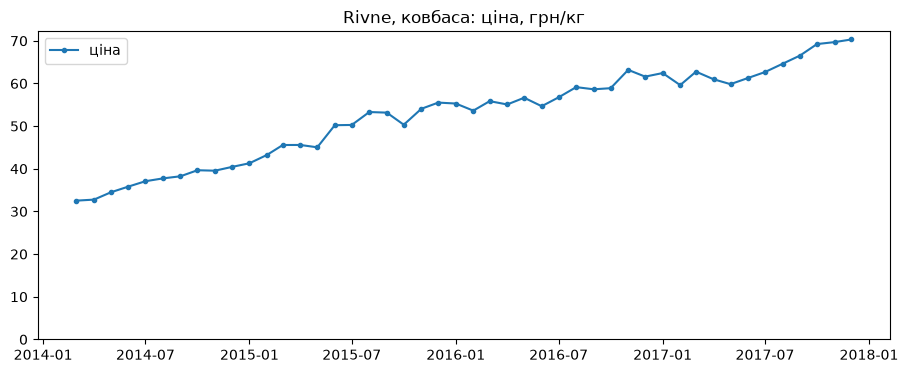

Ціна: 32.53 → 70.32 грн/кг, зросла в 2.16 раза


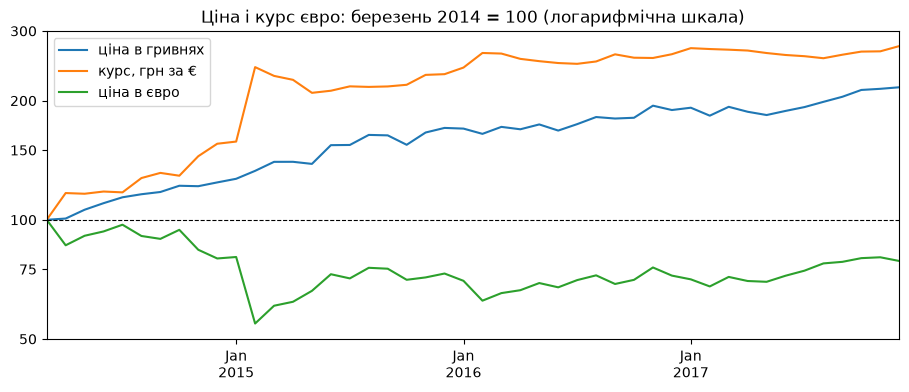

            ціна в гривнях  курс, грн за €  ціна в євро
2015-01-01           127.0           158.0         81.0
2015-02-01           133.0           243.0         55.0
2016-02-01           165.0           264.0         62.0
2017-12-01           216.0           275.0         79.0
Ціна в євро: 3.25 → 2.55 €/кг, мінімум 1.78 у 02.2015


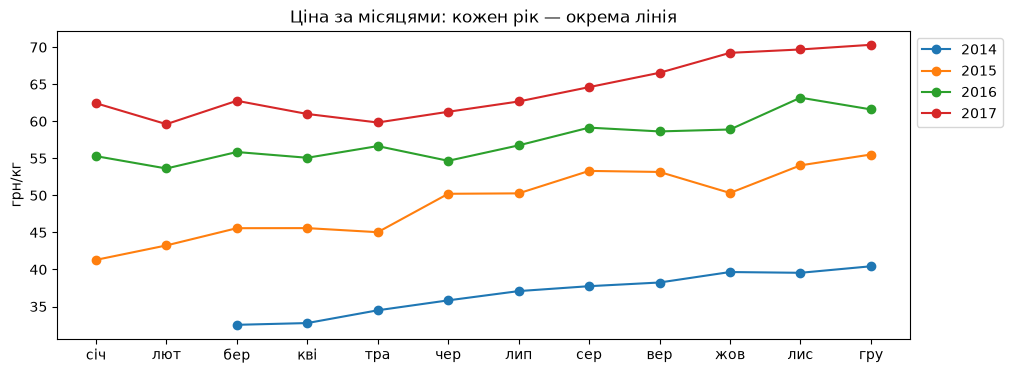

In [112]:
MONTHS_UA = ['січ', 'лют', 'бер', 'кві', 'тра', 'чер', 'лип', 'сер', 'вер', 'жов', 'лис', 'гру']


fig, ax = plt.subplots()
ax.plot(y.index, y, marker='o', ms=3, label='ціна')
# ax.plot(GAP, y[GAP], 'o', ms=8, mfc='white', mec='red', label='08.2017 — заповнено інтерполяцією')
ax.set_ylim(bottom=0)
ax.set_title(f'{MARKET}, {GOOD_UA}: ціна, грн/кг')
ax.legend(); plt.show()
print(f'Ціна: {y.iloc[0]:.2f} → {y.iloc[-1]:.2f} грн/кг, зросла в {y.iloc[-1] / y.iloc[0]:.2f} раза')


rates = pd.read_csv('курс_євро_1990_2021.csv')
rates.index = pd.to_datetime(dict(year=rates['рік'], month=rates['місяць'], day=1))
eur = rates['грн_за_євро'].reindex(GRID)

index = pd.DataFrame({'ціна в гривнях': y, 'курс, грн за €': eur, 'ціна в євро': y / eur})
index = index / index.iloc[0] * 100

ax = index.plot(logy=True, title='Ціна і курс євро: березень 2014 = 100 (логарифмічна шкала)')
ax.axhline(100, color='k', lw=0.8, ls='--')
ax.set_yticks([50, 75, 100, 150, 200, 300], labels=['50', '75', '100', '150', '200', '300'])
ax.minorticks_off(); plt.show()
print(index.loc[['2015-01-01', '2015-02-01', '2016-02-01', '2017-12-01']].round(0))
print(f'Ціна в євро: {y.iloc[0] / eur.iloc[0]:.2f} → {y.iloc[-1] / eur.iloc[-1]:.2f} €/кг, '
      f'мінімум {(y / eur).min():.2f} у {(y / eur).idxmin():%m.%Y}')


fig, ax = plt.subplots()
for year in y.index.year.unique():
    s = y[y.index.year == year]
    ax.plot(s.index.month, s, marker='o', label=year)
ax.set_xticks(range(1, 13), MONTHS_UA)
ax.set_ylabel('грн/кг')
ax.set_title('Ціна за місяцями: кожен рік — окрема лінія')
ax.legend(bbox_to_anchor=(1, 1), loc='upper left'); plt.show()

**Висновок до завдання 3:**

**Графік 1. Як змінювалась ціна і в скільки разів вона зросла?**
* *Геометрія:* лінія з точками. Ціна - це рівень у часі, сусідні місяці пов'язані, а точки показують виміри.
* *Шкала:* лінійна, вісь Y від нуля. Ціна має справжній нуль, тому висота точок прямо показує відношення.
* *Відповідь:* ціна зросла з 32.53 до 70.32 грн/кг, тобто у 2.16 рази, майже без спадів.

**Графік 2. Подорожчання справжнє чи це девальвація гривні?**
* *Геометрія:* три лінії зі спільною базою (03.2014 = 100). Ціна й курс мають різні одиниці, а дві осі Y дозволили б підігнати масштаб як завгодно.
* *Шкала:* логарифмічна. Питання стосується відношень, а на такій шкалі однакові відсоткові зміни мають однакову висоту.
* *Відповідь:* ціна в гривнях дійшла до 216, курс євро — до 275. Отже, у євро ковбаса подешевшала на 21 % (3.25 → 2.55 €/кг).

**Графік 3. Чи повторюються ті самі місяці з року в рік (сезонність)?**
* *Геометрія:* сезонний графік — окрема лінія для кожного року, по осі X календарний місяць. Якщо сезонність є, лінії різних років мають однакову форму: піки й спади в ті самі місяці. Лінія доречна, бо всередині року сусідні місяці пов'язані.
* *Шкала:* ціна в грн/кг, лінійна, вісь Y не від нуля. Питання тут про форму коливань усередині року, а не про відношення рівнів, тому вісь підігнано під дані, щоб коливання було видно. Лінії різних років стоять на різній висоті через тренд.
* *Відповідь:* спільної форми лінії не мають: у кожному році ціна здебільшого просто росте. Повторюється лише стрибок у **березні** (+4.1…+5.4 % щороку, див. таблицю). Липень і серпень теж щороку додатні (08.2017 інтерпольовано), а в інших місяцях знак змінюється з року в рік. Сезонність, якщо вона є, слабка; це перевіряє завдання 4.

**Неочікувана знахідка.** Я очікувала, що девальвація в лютому 2015 одразу «підкине» ціну. Насправді курс євро за місяць зріс на 54 % (індекс 158 → 243), а ціна в гривнях — лише на 5 % (127 → 133). Через це ціна в євро впала до мінімуму 1.78 €/кг. Далі гривнева ціна поступово доганяла курс: з 02.2016 до 12.2017 курс зріс лише на 4 %, а ціна — на 31 %. Девальвація переходить у ціну не стрибком, а із запізненням на роки.

## Завдання 4. Розкладання на складові

Розкладіть ряд на тренд, сезонну складову та залишок методом STL із періодом 12.

**У звіті наведіть:**
1. чотирипанельний графік розкладання;
2. числові значення сили сезонності $F_S$ та сили тренду $F_T$;
3. **висновок: чи є у вашому ряді сезонність**, із посиланням на порогове значення.

> 💡 **Підказка.** STL поверне сезонну складову завжди. Ваше завдання — вирішити, чи вона означає щось, а не чи вона є.

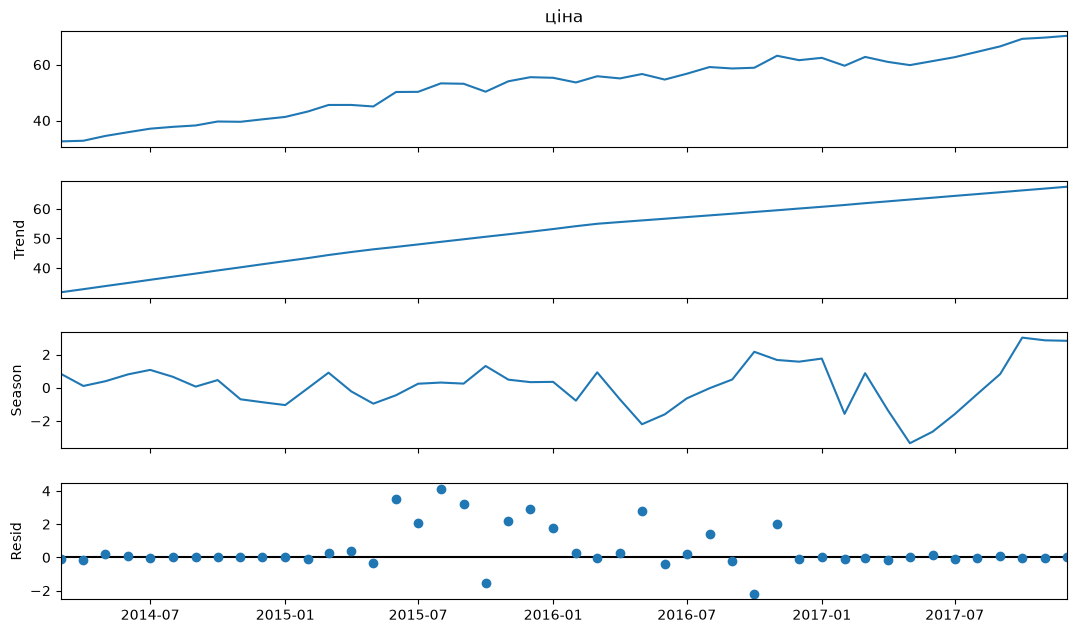

F_S = 0.48 (поріг 0.3), F_T = 0.99
2014    1.95
2015    2.35
2016    4.36
2017    6.36
Name: season, dtype: float64


In [99]:
from statsmodels.tsa.seasonal import STL

stl = STL(y, period=12, robust=True).fit()
stl.plot().set_size_inches(11, 7)
plt.show()

F_S = max(0, 1 - stl.resid.var() / (stl.seasonal + stl.resid).var())
F_T = max(0, 1 - stl.resid.var() / (stl.trend + stl.resid).var())
print(f'F_S = {F_S:.2f} (поріг 0.3), F_T = {F_T:.2f}')

print(stl.seasonal.groupby(stl.seasonal.index.year).agg(lambda s: s.max() - s.min()).round(2))

**Висновок до завдання 4:**

1. Графік розкладання — вище (ряд, тренд, сезонна складова, залишок; STL, період 12).
2. $F_S$ = **0.48**, $F_T$ = **0.99**.
3. **Сезонність є, але слабка й нестійка.** $F_S = 0.48$ лише трохи перевищує поріг 0.3. Сезонна складова не повторюється однаково: її розмах зростає з 1.95 грн у 2014 до 6.36 грн у 2017, а форма щороку інша. Майже всю мінливість ряду пояснює тренд ($F_T = 0.99$). Тому спиратися на сезонність у прогнозі ризиковано, тим паче що даних лише ~4 роки.

## Завдання 5. Стаціонарність

Побудуйте ACF і PACF вихідного ряду та його першої різниці. Застосуйте тести ADF і KPSS до обох.

**У звіті наведіть:**
1. графіки ACF і PACF до та після диференціювання;
2. таблицю з $p$-значеннями обох тестів для обох рядів;
3. висновок про стаціонарність **із зазначенням, узгоджуються тести між собою чи ні**;
4. якщо не узгоджуються — ваше пояснення, чому.

> 💡 **Підказка.** Нульові гіпотези ADF і KPSS протилежні. Перш ніж писати висновок, перевірте, що ви не переплутали напрямок.

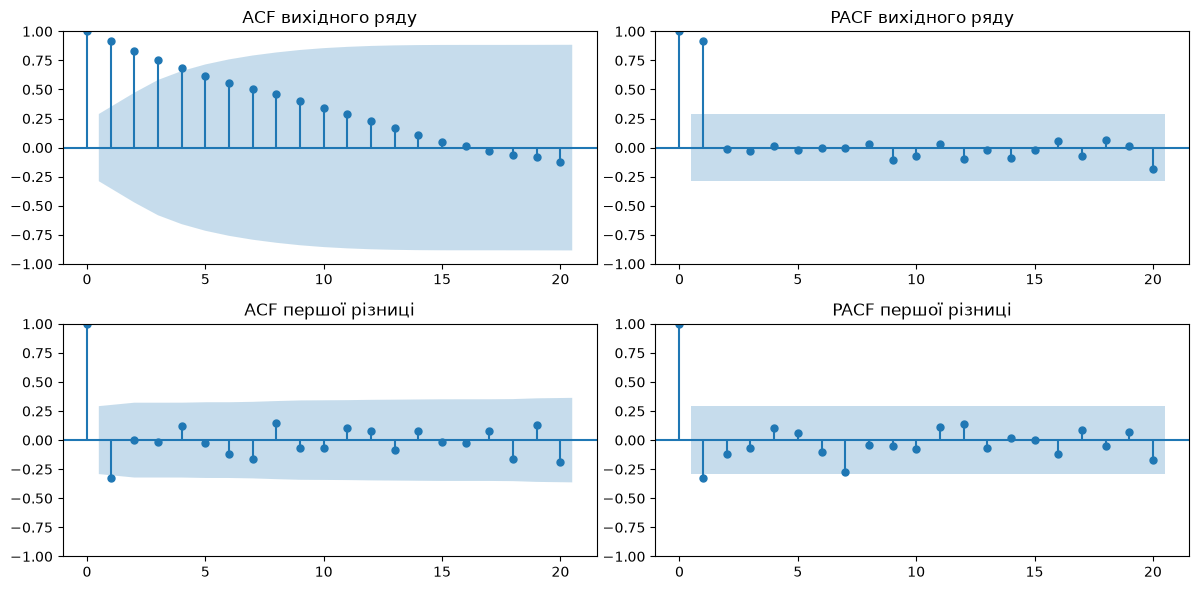

,ADF p,KPSS p
вихідний ряд,0.755,0.01
перша різниця,0.000,0.10


In [ ]:
import warnings
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

warnings.filterwarnings('ignore')   

dy = y.diff().dropna()

fig, axes = plt.subplots(2, 2, figsize=(12, 6))
plot_acf(y, lags=20, ax=axes[0, 0], title='ACF вихідного ряду')
plot_pacf(y, lags=20, ax=axes[0, 1], title='PACF вихідного ряду')
plot_acf(dy, lags=20, ax=axes[1, 0], title='ACF першої різниці')
plot_pacf(dy, lags=20, ax=axes[1, 1], title='PACF першої різниці')
plt.tight_layout(); plt.show()

pd.DataFrame({'ADF p':  [adfuller(y)[1], adfuller(dy)[1]],
              'KPSS p': [kpss(y)[1], kpss(dy)[1]]},
             index=['вихідний ряд', 'перша різниця']).round(3)

**Висновок до завдання 5:**

1. **ACF і PACF** — графіки вище.
   * *Вихідний ряд:* ACF спадає повільно (0.91, 0.83, 0.75, …), лаги 1–4 виходять за смугу. Це типовий нестаціонарний ряд із трендом. PACF має один сплеск на лагу 1 (0.91).
   * *Перша різниця:* значущий лише лаг 1 (−0.33) і в ACF, і в PACF, решта в смузі шуму. 
2. **p-значення** (ADF: H₀ — ряд нестаціонарний; KPSS: H₀ — ряд стаціонарний):

   | Ряд | ADF p | KPSS p |
   |---|---|---|
   | вихідний ряд | 0.755 | 0.01 |
   | перша різниця | 0.000 | 0.10 |

3. Вихідний ряд **нестаціонарний**: ADF не відкидає H₀, KPSS відкидає. Перша різниця **стаціонарна**: ADF відкидає H₀, KPSS не відкидає. **Тести узгоджуються** для обох рядів, тож $d = 1$.
4. Розбіжності між тестами немає, пояснення не потрібне.

## Завдання 6. Базисні прогнози та ретроспективна перевірка

Побудуйте **чотири** базисні прогнози: наївний, сезонний наївний, середнє та дрейф.
Оцініть їх **ретроспективною перевіркою з рухомим початком**: **7 фолдів по 3 кроки**,
навчальна частина розширюється.

**У звіті наведіть:**
1. таблицю MAE, RMSE і MAPE для всіх чотирьох базисів;
2. який базис виявився найкращим і **чому саме він** — поясніть через властивості вашого ряду;
3. для порівняння: ту саму оцінку, зроблену звичайним випадковим поділом 75/25, і **у скільки разів** вона відрізняється.

> 💡 **Підказка.** Кількість фолдів і кроків задана жорстко — у Частині 2 вона має збігтися з налаштуваннями Orange.

In [ ]:
N_FOLDS, H = 7, 3
BASELINES = ['наївний', 'сезонний наївний', 'середнє', 'дрейф']

def metrics(actual, pred):
    """MAE, RMSE, MAPE (звичайні означення); пари, де прогнозу немає (NaN), пропускаються."""
    actual, pred = np.asarray(actual, float), np.asarray(pred, float)
    ok = ~np.isnan(pred)
    e = actual[ok] - pred[ok]
    return {'MAE': np.mean(np.abs(e)), 'RMSE': np.sqrt(np.mean(e ** 2)),
            'MAPE': np.mean(np.abs(e / actual[ok])) * 100}

def forecast(train, t):
    """Прогнози чотирьох базисів для місяця t, якщо відомі лише місяці train (номери 0…45)."""
    v = y.values
    past = [i for i in train if i < t]               
    if len(past) < 2:                                
        return dict.fromkeys(BASELINES, np.nan)
    first, last = past[0], past[-1]
    year_ago = [i for i in past if i <= t - 12]      
    return {
        'наївний':          v[last],
        'сезонний наївний': v[year_ago[-1]] if year_ago else np.nan,
        'середнє':          v[train].mean(),
        'дрейф':            v[last] + (v[last] - v[first]) / (last - first) * (t - last),
    }

def evaluate(splits):
    pred = pd.DataFrame([forecast(train, t) for train, test in splits for t in test])
    actual = [y.iloc[t] for train, test in splits for t in test]
    return pd.DataFrame({name: metrics(actual, pred[name]) for name in BASELINES}).T

origins = [len(y) - k * H for k in range(N_FOLDS, 0, -1)]      
roll = evaluate([(list(range(o)), range(o, o + H)) for o in origins])
for o in origins:
    print(f'навчання {y.index[0]:%m.%Y}–{y.index[o - 1]:%m.%Y} ({o} міс.) → тест {y.index[o]:%m.%Y}–{y.index[o + H - 1]:%m.%Y}')


rng = np.random.default_rng(0)
rand = []
for _ in range(200):
    perm = rng.permutation(len(y))
    rand.append(evaluate([(sorted(perm[:34]), sorted(perm[34:]))]))
rand = sum(rand) / len(rand)

print('\nРухомий початок, 7 фолдів × 3 кроки:');            display(roll.round(2))
print('Випадковий поділ 75/25 (середнє по 200 розбиттях):'); display(rand.round(2))
print('У скільки разів рухомий початок дає більшу помилку:'); display((roll / rand).round(2))

навчання 03.2014–03.2016 (25 міс.) → тест 04.2016–06.2016
навчання 03.2014–06.2016 (28 міс.) → тест 07.2016–09.2016
навчання 03.2014–09.2016 (31 міс.) → тест 10.2016–12.2016
навчання 03.2014–12.2016 (34 міс.) → тест 01.2017–03.2017
навчання 03.2014–03.2017 (37 міс.) → тест 04.2017–06.2017
навчання 03.2014–06.2017 (40 міс.) → тест 07.2017–09.2017
навчання 03.2014–09.2017 (43 міс.) → тест 10.2017–12.2017

Рухомий початок, 7 фолдів × 3 кроки:


,MAE,RMSE,MAPE
наївний,2.42,2.80,3.87
сезонний наївний,7.04,7.31,11.44
середнє,13.45,13.71,21.64
дрейф,2.06,2.42,3.38


Випадковий поділ 75/25 (середнє по 200 розбиттях):


,MAE,RMSE,MAPE
наївний,1.85,2.25,3.48
сезонний наївний,9.59,10.17,17.19
середнє,8.46,9.86,16.79
дрейф,1.58,1.94,2.91


У скільки разів рухомий початок дає більшу помилку:


,MAE,RMSE,MAPE
наївний,1.31,1.24,1.11
сезонний наївний,0.73,0.72,0.67
середнє,1.59,1.39,1.29
дрейф,1.30,1.24,1.16


**Висновок до завдання 6:**

Схема така сама, як в Orange: у фолді *k* модель навчається на всіх місяцях до `y[-3k]` і прогнозує наступні 3. Навчальна частина розширюється з 25 до 43 місяців, тест покриває 04.2016–12.2017 (21 прогноз).

1. **Рухомий початок, 7 фолдів × 3 кроки:**

   | Базис | MAE, грн | RMSE, грн | MAPE, % |
   |---|---|---|---|
   | **дрейф** | **2.06** | **2.42** | **3.38** |
   | наївний | 2.42 | 2.80 | 3.87 |
   | сезонний наївний | 7.04 | 7.31 | 11.44 |
   | середнє | 13.45 | 13.71 | 21.64 |

2. **Найкращий — дрейф**, за всіма трьома метриками. Ряд поводиться як випадкове блукання зі зсувом: сильний рівномірний тренд ($F_T$ = 0.99) і стаціонарна перша різниця. Дрейф продовжує останнє значення із середнім приростом (~0.84 грн/міс.), а саме це ряду й потрібно. **Наївний** стартує з правильного рівня, але не враховує зростання. **Сезонний наївний** бере ціну річної давнини, а за рік ціна змінювалась у середньому на ~7 грн; слабка сезонність цього не компенсує. **Середнє** змішує ціни 2014 і 2017 років і на ряді з трендом не має сенсу.
3. **Випадковий поділ 75/25** (34 / 12 міс., середнє по 200 розбиттях) дає для дрейфу MAE 1.58 замість 2.06, тобто **занижує помилку в 1.30 раза** (RMSE — у 1.24, MAPE — у 1.16). Для наївного прогнозу занижено в 1.31 раза, для середнього — в 1.59. Причина — витік даних: тестові місяці оточені навчальними з обох боків, тож прогноз стає інтерполяцією, а середнє «бачить» майбутні ціни. Виняток — сезонний наївний (0.73): за випадкового поділу значення рівно рік тому часто немає серед навчальних, і він бере ще старіше. Але й ця оцінка некоректна; чесною є лише оцінка з рухомим початком.

## Завдання 7. Модель ARIMA

Побудуйте модель ARIMA і оцініть її **на тих самих 7 фолдах по 3 кроки**.

Обов'язково використайте порядок **(1, 1, 1)** — саме його ви відтворюватимете в Orange.
Додатково визначте, який порядок $(p, d, q)$ ви обрали б **за виглядом ACF і PACF** із завдання 5.

**У звіті наведіть:**
1. MAE, RMSE і MAPE моделі ARIMA(1,1,1) на рухомому початку;
2. обґрунтування порядку, який ви обрали б самостійно, з посиланням на конкретні лаги;
3. **порівняння з найкращим базисом із завдання 6** — і прямий висновок, чи має ця модель право на існування;
4. графік залишків моделі та висновок, чи лишилася в них структура.

> 💡 **Підказка.** Якщо ARIMA програла базису — це законний результат, а не помилка. Напишіть про це прямо.

,MAE,RMSE,MAPE
"ARIMA(1,1,1)",2.34,2.73,3.74
дрейф,2.06,2.42,3.38
наївний,2.42,2.80,3.87


ar.L1     1.000
ma.L1    -0.998
sigma2    3.121
dtype: float64


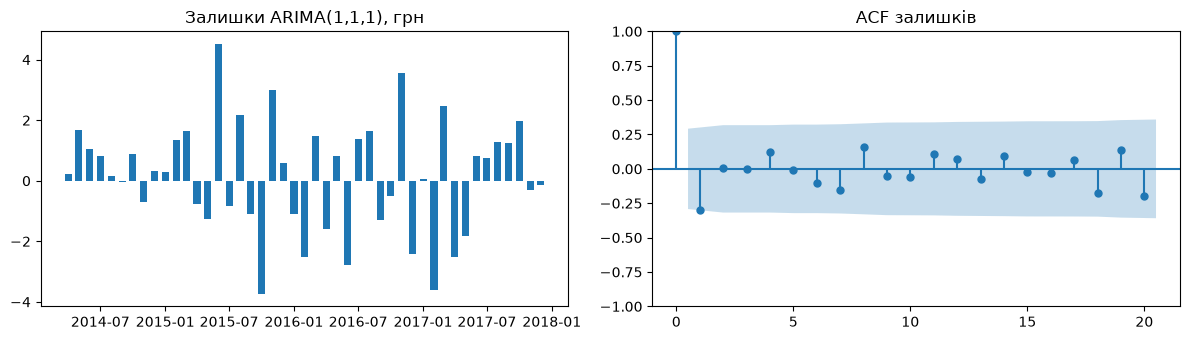

Тест Льюнга–Бокса (H0: залишки — білий шум):


,lb_stat,lb_pvalue
6,5.734,0.454
12,9.846,0.629


In [ ]:
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.stats.diagnostic import acorr_ljungbox

actual     = pd.concat([y.iloc[o:o + H] for o in origins])
arima_pred = pd.concat([ARIMA(y.iloc[:o], order=(1, 1, 1)).fit().forecast(H) for o in origins])

comparison = pd.DataFrame({'ARIMA(1,1,1)': metrics(actual, arima_pred),
                           'дрейф':        roll.loc['дрейф'],
                           'наївний':      roll.loc['наївний']}).T
display(comparison.round(2))

full_fit = ARIMA(y, order=(1, 1, 1)).fit()
print(full_fit.params.round(3))
resid = full_fit.resid.iloc[1:]       

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].bar(resid.index, resid, width=20)
axes[0].set_title('Залишки ARIMA(1,1,1), грн')
plot_acf(resid, lags=20, ax=axes[1], title='ACF залишків')
plt.tight_layout(); plt.show()

**Висновок до завдання 7:**

1. **Метрики на тих самих 7 фолдах:**

   | Модель | MAE, грн | RMSE, грн | MAPE, % |
   |---|---|---|---|
   | ARIMA(1,1,1) | 2.34 | 2.73 | 3.74 |
   | **дрейф (найкращий базис)** | **2.06** | **2.42** | **3.38** |
   | наївний | 2.42 | 2.80 | 3.87 |

2. **За ACF/PACF я обрала б ARIMA(0,1,1).**
   * $d = 1$: так показали ACF і тести із завдання 5.
   * $q = 1$: ACF першої різниці обривається після лагу 1 (−0.33).
   * $p = 0$: у PACF теж значущий лише лаг 1 (−0.33), тож (1,1,0) — рівноцінна альтернатива. Проте від'ємний лаг 1 в ACF більше схожий на MA(1).
   * Сезонних лагів (12) немає.

   ARIMA(1,1,1) має зайвий параметр. На всьому ряді φ = 1.000, θ = −0.998, тобто AR- і MA-частини майже взаємно знищуються.
3. **ARIMA(1,1,1) програла дрейфу** за всіма метриками (MAE 2.34 проти 2.06, на 14 % гірше) і майже не відрізняється від наївного прогнозу. У 5 із 7 фолдів її прогноз практично плаский: константи немає, тож тренд модель не продовжує. **Висновок: для цього ряду ARIMA(1,1,1) права на існування не має**, бо простий дрейф точніший.
4. **Залишки** коливаються навколо нуля без тренду. В ACF лише лаг 1 (≈ −0.30) біля межі смуги, а тест Льюнга–Бокса не відкидає H₀ про білий шум (p = 0.45 для 6 лагів, 0.63 для 12). **Структури в залишках не лишилось.** Модель програє не через невикористану автокореляцію, а тому, що не прогнозує тренд.

## Завдання 8. Точка зміни режиму

Знайдіть у своєму ряді точку, після якої змінюється **рівень** ряду.
Скористайтеся скануванням: для кожної кандидатної дати порівняйте середні до і після
та оберіть дату з найбільшою t-статистикою.

**У звіті наведіть:**
1. графік ряду з позначеною знайденою датою;
2. дату, значення t-статистики, середні рівні до і після;
3. **чи є ця точка значущою** — і якщо ні, так і напишіть;
4. чим знайдена точка відрізняється від звичайного сезонного сплеску у вашому ряді.

> 💡 **Підказка.** Не плутайте зсув рівня з сезонним піком. Якщо «аномалії» повторюються щороку в ті самі місяці — це сезон.

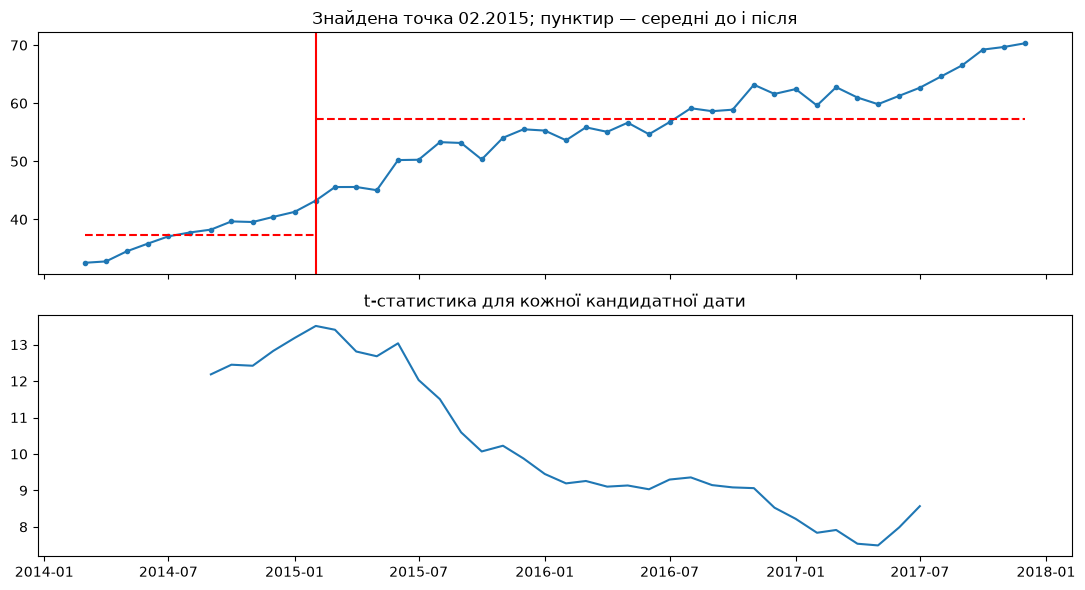

Точка 02.2015: t = 13.51; середнє до 37.24 (11 міс.), після 57.30 грн/кг (35 міс.)
Ряди без зсуву: медіана max|t| = 14.0; частка з max|t| ≥ 13.5: p = 0.61


In [ ]:
from scipy.stats import ttest_ind

def scan(v, min_seg=6):
    return pd.Series({k: ttest_ind(v[k:], v[:k], equal_var=False).statistic
                      for k in range(min_seg, len(v) - min_seg + 1)})

t_scan = scan(y.values)
k = t_scan.abs().idxmax()
cp = y.index[k]
before, after = y.iloc[:k].mean(), y.iloc[k:].mean()

fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
axes[0].plot(y.index, y, marker='o', ms=3)
axes[0].axvline(cp, color='red')
axes[0].hlines([before, after], [y.index[0], cp], [cp, y.index[-1]], colors='red', ls='--')
axes[0].set_title(f'Знайдена точка {cp:%m.%Y}; пунктир — середні до і після')
axes[1].plot(y.index[t_scan.index], t_scan)
axes[1].set_title('t-статистика для кожної кандидатної дати')
plt.tight_layout(); plt.show()
print(f'Точка {cp:%m.%Y}: t = {t_scan[k]:.2f}; середнє до {before:.2f} ({k} міс.), після {after:.2f} грн/кг ({len(y) - k} міс.)')

# Значущість: те саме сканування на 1000 рядах БЕЗ зсуву рівня — випадкових блуканнях,
# складених із місячних приростів нашого ряду, взятих у випадковому порядку
rng = np.random.default_rng(0)
steps = np.diff(y.values)
t_null = np.array([scan(y.iloc[0] + np.r_[0, np.cumsum(rng.permutation(steps))]).abs().max()
                   for _ in range(1000)])
print(f'Ряди без зсуву: медіана max|t| = {np.median(t_null):.1f}; частка з max|t| ≥ {abs(t_scan[k]):.1f}: p = {np.mean(t_null >= abs(t_scan[k])):.2f}')

**Висновок до завдання 8:**

1. Графік — вище: ряд із знайденою датою й середніми до і після, а під ним t-статистика для кожної дати. Кандидатами були дати, що мають щонайменше 6 місяців з кожного боку.
2. Дата — **02.2015**, t = **13.51**. Середнє **до** — 37.24 грн/кг (11 міс.), **після** — 57.30 грн/кг (35 міс.).
3. **Точка не значуща.** Табличне p для t = 13.5 мізерне, але тут воно некоректне, і причин три:
   * спостереження залежні (ACF лаг 1 = 0.91);
   * обрано максимум із 35 t-статистик;
   * головне — у ряді є тренд, тому будь-який поділ дає «після» вище за «до». На нижній панелі t від 7.5 до 13.5 для всіх дат, а різкого піку немає.

   Тому я застосувала те саме сканування до 1000 рядів без зсуву рівня (випадкові блукання з тими самими місячними приростами). Медіана max|t| у них — 13.8, тобто більша за нашу, а **p = 0.57**. Отже, значущої зміни рівня немає. Дата збігається з девальвацією (завдання 3), але в ціні видно лише продовження плавного зростання.
4. **Сезонний сплеск** повторюється щороку в ті самі місяці, після чого ряд повертається до звичного рівня. У нас це березневе подорожчання на 4–5 % (завдання 3). Знайдена точка одноразова, і ряд після неї назад не повертається. Так виглядала б зміна режиму, але тут «неповернення» пояснює тренд. Справжній зсув дав би різкий пік t, а його немає.

## Завдання 9. Рецензія на чужий аналіз

Відкрийте `ЛР4_помилковий_аналіз.ipynb`. Це звіт, зроблений на іншому ряді з того самого набору.
Він виконується без помилок і виглядає переконливо, але містить **методологічні помилки**.

**У звіті наведіть:**
1. перелік знайдених помилок — для кожної вкажіть номер клітинки, суть помилки й **чим вона небезпечна**;
2. для трьох найсерйозніших — як саме їх виправити.

> 💡 **Підказка.** Помилок щонайменше вісім. Шукайте не синтаксис, а порушення принципів роботи з часовими рядами.

In [115]:
bw   = get_series('Vinnytsia', 'Buckwheat grits - Retail').interpolate()
beef = get_series('Vinnytsia', 'Meat (beef) - Retail').interpolate()
lviv = get_series('Lviv', 'Buckwheat grits - Retail').interpolate()

for name, x in [('гречка', bw), ('яловичина', beef)]:                   
    m = metrics(x.iloc[1:], x.shift(1).iloc[1:])
    print(f'In[4]  {name}: MAE = {m["MAE"]:.2f} грн, MAPE = {m["MAPE"]:.1f} %')

print(f'In[5]  кореляція рівнів {bw.corr(lviv):.3f}, місячних змін {bw.diff().corr(lviv.diff()):.2f}')

res = STL(bw, period=12, robust=True).fit()
print(f'In[6]  F_S = {1 - res.resid.var() / (res.seasonal + res.resid).var():.2f}')

for name, x in [('рівень', bw), ('перша різниця', bw.diff().dropna())]:
    print(f'In[7]  {name}: ADF p = {adfuller(x)[1]:.3f}, KPSS p = {kpss(x)[1]:.3f}')

print(f'In[9]  MAE колеги 8.73 грн = {8.73 / bw.mean() * 100:.0f} % середньої ціни ({bw.mean():.2f} грн)')
print(f'In[10] прогноз 8.95 грн при останній ціні {bw.iloc[-1]:.2f} грн: {(8.95 / bw.iloc[-1] - 1) * 100:+.0f} %')

In[4]  гречка: MAE = 1.35 грн, MAPE = 6.1 %
In[4]  яловичина: MAE = 1.47 грн, MAPE = 1.9 %
In[5]  кореляція рівнів 0.996, місячних змін 0.94
In[6]  F_S = 0.26
In[7]  рівень: ADF p = 0.348, KPSS p = 0.018
In[7]  перша різниця: ADF p = 0.040, KPSS p = 0.065
In[9]  MAE колеги 8.73 грн = 41 % середньої ціни (21.36 грн)
In[10] прогноз 8.95 грн при останній ціні 17.67 грн: -49 %


**Висновок до завдання 9:**

Номери клітинок — за `In [n]` у `ЛР4_помилковий_аналіз.ipynb`. Числа перевірено кодом вище на тому самому ряді (гречка, Вінниця).

**1. Перелік помилок**

| № | Клітинка | Помилка | Чим небезпечна |
|---|---|---|---|
| 1 | In[1]–In[2] | Ряд не приведено до повної сітки, тому `isna()` не бачить відсутнього рядка за 08.2017 (45 значень замість 46). Висновок «пропусків немає» хибний. | Усе, що спирається на сусідні місяці (`shift`, ACF, STL, ARIMA), після 07.2017 зсувається на місяць. Помилка тихо псує подальші результати (MAE в In[4] 1.38 замість 1.35). |
| 2 | In[3] | Подорожчання оцінено за двома точками в номінальних гривнях, і з цього зроблено висновок про «зниження купівельної спроможності». | Доходів та інфляції в даних немає, а гривня за цей час знецінилась у ~2.7 раза щодо євро. Висновок не випливає з даних і залежить від вибору двох місяців. |
| 3 | In[4] | Точність прогнозу різних товарів порівняно за MAE у гривнях, хоча яловичина в ~4 рази дорожча. | Висновок перевернутий: за MAPE яловичина прогнозується втричі краще (1.9 % проти 6.1 %). Між рядами порівнюють MAPE або MASE. |
| 4 | In[5] | Кореляцію рівнів двох рядів із трендом (r = 0.996) подано як доказ, що Львів «визначає» Вінницю. | Ряди з трендом корелюють майже завжди. Кореляція змін теж висока (0.94), але напрямку впливу вона не показує: найімовірніше, обидва ринки реагують на спільні чинники. |
| 5 | In[6] | «STL виділив сезонну складову, отже ряд сезонний». | STL повертає сезонну складову завжди. Тут $F_S$ = 0.26 < 0.3, тобто сезонності немає, а далі колега застосовує сезонні моделі до шуму. |
| 6 | In[7] | Хибно прочитано ADF: p = 0.233 > 0.05 означає, що ряд **не**стаціонарний. Потім ряд «для надійності» продиференційовано двічі, а KPSS не застосовано. | Хибне $d$: спершу 0, потім надмірне 2, хоча вже перша різниця стаціонарна (ADF p = 0.04, KPSS p = 0.065). Зайве диференціювання додає штучну автокореляцію; звідси ARIMA(2,2,1) в In[10]. |
| 7 | In[8] | Аномалії шукають за z-оцінкою вихідного ряду з трендом, ще й з порогом 1.3σ замість заявлених 2σ. | «Аномаліями» стають просто найнижчі (2014) і найвищі (2016) ціни, 12 із 45 місяців. Аномалії треба шукати в залишках після зняття тренду й сезонності. |
| 8 | In[9] | Часовий ряд поділено випадково (`train_test_split`). ARIMA навчено на склеєних несусідніх місяцях, прогноз порівняно з **відсортованими** тестовими значеннями, а сезонний наївний оцінено на всьому ряді. | Витік даних і порівняння непорівнянного, тож оцінка безглузда. До того ж MAE 8.73 грн — це 41 % середньої ціни (у наївного прогнозу 1.35 грн), а висновок каже «висока точність». |
| 9 | In[10] | Прогноз зроблено іншою моделлю, ARIMA(2,2,1), яку ніхто не оцінював, без дат і без інтервалу. Прогноз на 12.2018 — 8.95 грн (−49 % від 17.67), а висновок каже «ціна зростатиме». | Текст суперечить власному числу, тож читач отримує протилежну інформацію. |

**2. Як виправити три найсерйозніші**

* **(а) In[9] — оцінювання моделі.** Ділити ряд лише за часом, рухомим початком (наприклад, 7 фолдів × 3 кроки). Прогнози й факти порівнювати в хронологічному порядку. На тих самих фолдах оцінити базиси й порівняти модель із найкращим із них, а похибку подавати разом із MAPE чи MASE.
* **(б) In[7] — стаціонарність.** Пам'ятати, що в ADF H₀ — «ряд нестаціонарний», а в KPSS — «стаціонарний». Застосувати обидва тести до рівня й першої різниці. Тут рівень нестаціонарний (ADF p = 0.35, KPSS p = 0.02), а перша різниця стаціонарна, отже $d = 1$. Другу різницю брати лише тоді, коли перша нестаціонарна.
* **(в) In[1]–In[2] — пропуск.** Одразу привести ряд до повної сітки: `s.reindex(pd.date_range('2014-03-01', '2017-12-01', freq='MS'))`. Пояснити причину пропуску, заповнити його інтерполяцією і далі працювати з рядом із датами, а не з «голим» масивом.

## Завдання 10. Експорт ряду для Orange

Збережіть підготовлений ряд у файл `ряд_для_orange.csv` **рівно у такому вигляді**:

| Стовпець | Тип | Зміст |
|---|---|---|
| `date` | текст у форматі `РРРР-ММ-ДД` | перше число місяця |
| `price` | число | ціна, пропуск уже заповнений |

Один рядок на місяць, 46 рядків плюс заголовок, роздільник — кома, кодування UTF-8.

**У звіті наведіть:**
1. підтвердження, що файл має 46 рядків даних і не містить порожніх значень.

> 💡 **Підказка.** Формат заданий жорстко: Orange має отримати **точно ті самі** дані, що й Python, інакше порівняння в Частині 2 втрачає сенс.

In [ ]:
pd.DataFrame({'date': y.index.strftime('%Y-%m-%d'), 'price': y.values}).to_csv('ряд_для_orange.csv', index=False)

check = pd.read_csv('ряд_для_orange.csv')
print('Рядків даних:', len(check), '| порожніх значень:', check.isna().sum().sum(),
      '| збігається з y:', np.allclose(check['price'], y))
print(check.head(3))

Рядків даних: 46 | порожніх значень: 0 | збігається з y: True
         date    price
0  2014-03-01  32.5300
1  2014-04-01  32.7667
2  2014-05-01  34.4900


**Висновок до завдання 10:**

1. Файл `ряд_для_orange.csv` має **46 рядків даних** (плюс заголовок) і **жодного порожнього значення**. Стовпці `date` (РРРР-ММ-ДД, перше число місяця) і `price`, роздільник — кома, кодування UTF-8. Значення збігаються з рядом `y` (08.2017 = 64.61 після інтерполяції), тож Orange отримає ті самі дані, що й Python.

---
# ЧАСТИНА 2. Той самий аналіз засобами Orange

*Виконується самостійно.*

Потрібен додаток **Timeseries**: у Orange відкрийте *Options → Add-ons…* і встановіть `Orange3-Timeseries`.

**Головна умова цієї частини:** Orange має отримати **ті самі дані** й **ті самі налаштування перевірки**,
що й Python у Частині 1. Тоді будь-яка розбіжність у числах пояснюється **лише означеннями метрик**,
а не різними даними чи різними моделями. Саме це вам і треба довести.

## Завдання 11. Потік опрацювання даних

Побудуйте в Orange потік:

`File` → `As Timeseries` → `Interpolate` → `Line Chart`

У віджеті **File** завантажте свій `ряд_для_orange.csv`; переконайтеся, що `date` розпізнано
як **time**, а `price` — як **numeric**. У віджеті **As Timeseries** оберіть `date` як часову змінну.

**У звіті наведіть:**
1. знімок екрана з побудованим потоком;
2. знімок `Line Chart` із вашим рядом;
3. підтвердження, що графік у Orange збігається з графіком із завдання 3.

> 💡 **Підказка.** Якщо `date` розпізнано як текст, поверніться до завдання 10 і перевірте формат дати.

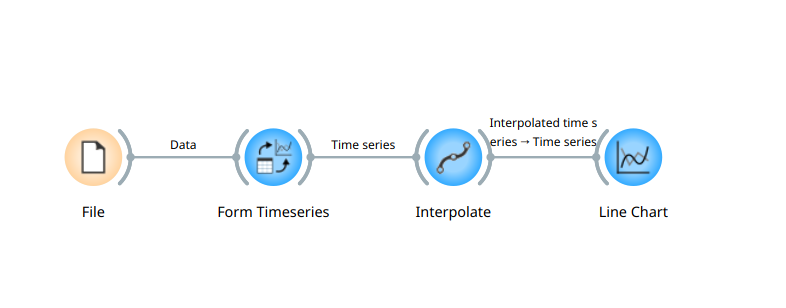

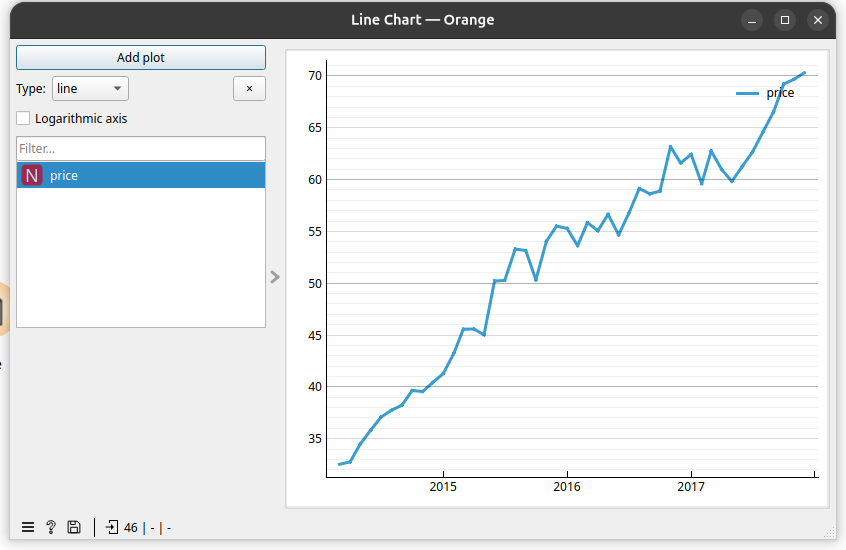

Перша точка 03.2014: 32.53, остання 12.2017: 70.32
Найбільші місячні спади: 10.2015 (-2.84), 02.2017 (-2.83), 06.2016 (-1.99)


In [ ]:
from IPython.display import Image
display(Image('Побудований потік.png'), Image('LineChart.png'))

print(f'Перша точка {y.index[0]:%m.%Y}: {y.iloc[0]:.2f}, остання {y.index[-1]:%m.%Y}: {y.iloc[-1]:.2f}')
print('Найбільші місячні спади:', ', '.join(f'{d:%m.%Y} ({v:+.2f})' for d, v in y.diff().nsmallest(3).items()))

**Висновок до завдання 11:**

1. **Потік** — перший знімок: `File → Form Timeseries → Interpolate → Line Chart`. У Timeseries 0.6.3 віджет As Timeseries називається Form Timeseries; часовою змінною в ньому обрано `date`. У File стовпець `date` розпізнано як **time**, `price` — як **numeric**. Повний потік збережено в `потік_orange.ows`.
2. **Line Chart** — другий знімок.
3. **Графік Orange збігається з графіком 1 завдання 3.** Збігаються початок (32.53, 03.2014), кінець (70.32, 12.2017) і три найбільші спади (10.2015, 02.2017, 06.2016). Відрізняється лише шкала: Orange починає вісь Y з ~32, а не з нуля, тому зростання виглядає крутішим.

## Завдання 12. Автокореляція та диференціювання

Додайте до потоку віджети `Correlogram`, `Difference` та `Seasonal Adjustment`.

**У звіті наведіть:**
1. знімок корелограми;
2. зіставлення з ACF із завдання 5: **чи збігаються висновки** про значущі лаги;
3. знімок сезонно скоригованого ряду та порівняння з сезонною складовою STL із завдання 4.

> 💡 **Підказка.** Orange і statsmodels рахують автокореляцію однаково — якщо картина різна, перевірте, чи однакові дані на вході.

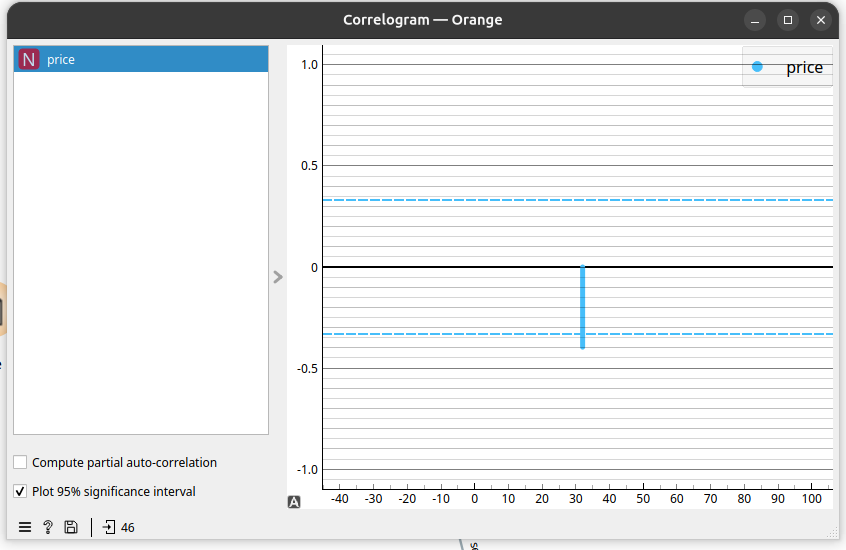

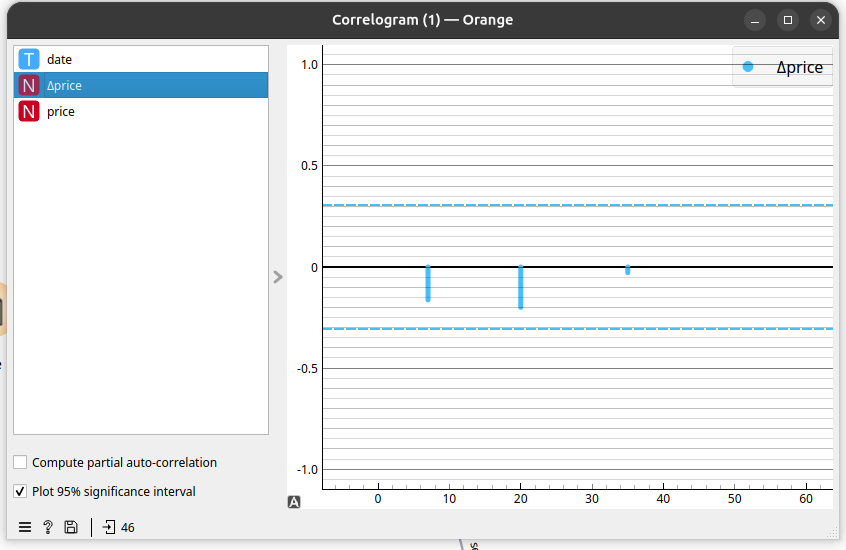

Orange, вихідний ряд:  лаг 32: -0.397
Orange, перша різниця: лаг 7: -0.163, лаг 20: -0.200, лаг 35: -0.028


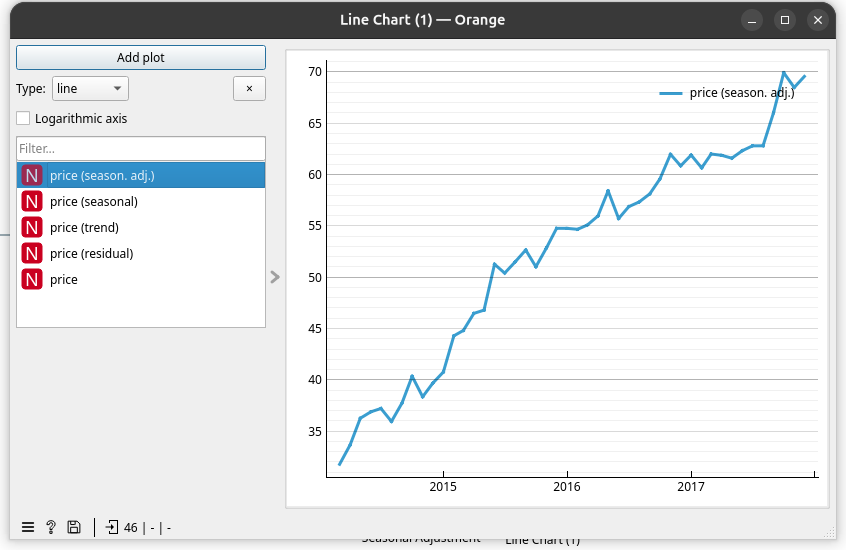

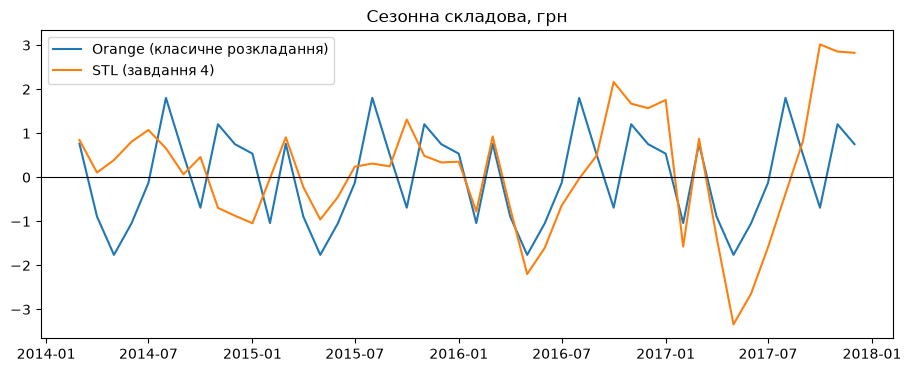

Розмах сезонної складової за роками, грн:
        2014  2015  2016  2017
Orange  3.56  3.56  3.56  3.56
STL     1.95  2.35  4.36  6.36
Кореляція двох сезонних складових: 0.43


In [ ]:
from statsmodels.tsa.stattools import acf
from statsmodels.tsa.seasonal import seasonal_decompose
from scipy.signal import argrelextrema

display(Image('Корелограма.png'), Image('Correlogram_diff.png'))

def orange_lags(x):
    """Які лаги показує Correlogram в Orange: ACF до лагу 0.9·n, але лише там,
    де |ACF| більша, ніж у трьох сусідів з кожного боку (functions.py, _significant_acf)."""
    a = acf(x, nlags=int(0.9 * len(x)))
    lags = argrelextrema(np.abs(a), np.greater, order=3)[0]
    return ', '.join(f'лаг {l}: {a[l]:.3f}' for l in lags)

print('Orange, вихідний ряд: ', orange_lags(y))
print('Orange, перша різниця:', orange_lags(y.diff().bfill()))  

display(Image('LineChart2.png'))
classic = seasonal_decompose(y, model='additive', period=12)

fig, ax = plt.subplots()
ax.plot(classic.seasonal, label='Orange (класичне розкладання)')
ax.plot(stl.seasonal, label='STL (завдання 4)')
ax.axhline(0, color='k', lw=0.8)
ax.set_title('Сезонна складова, грн'); ax.legend(); plt.show()

amplitude = lambda s: s.groupby(s.index.year).agg(lambda v: v.max() - v.min())
print('Розмах сезонної складової за роками, грн:')
print(pd.DataFrame({'Orange': amplitude(classic.seasonal), 'STL': amplitude(stl.seasonal)}).round(2).T)
print(f'Кореляція двох сезонних складових: {classic.seasonal.corr(stl.seasonal):.2f}')

**Висновок до завдання 12:**

1. **Корелограми** — перші два знімки: вихідний ряд і перша різниця (віджет `Difference`, First order difference).
2. **Порівняння з ACF із завдання 5.** Самі значення ACF в Orange і statsmodels однакові: код вище відтворює стовпчики Orange. Проте Orange показує лише лаги, де |ACF| — локальний максимум (функція `_significant_acf`), тому **висновки збігаються лише частково**:
   * *вихідний ряд:* у Python значущі лаги 1–4 і ACF повільно спадає, що є ознакою нестаціонарності. В Orange видно лише лаг 32 (−0.40): ACF спадає монотонно, тож «піків» не має;
   * *перша різниця:* обидва інструменти показують, що автокореляції майже немає. Але значущого в Python лагу 1 (−0.33) Orange не показує; його лаги 7, 20 і 35 лежать усередині смуги;
   * сезонних піків на лагах 12 і 24 немає в жодному інструменті, і тут висновки збігаються.
3. **Сезонно скоригований ряд** — знімок `Line Chart (1)`. `Seasonal Adjustment` в Orange — це не STL, а класичне розкладання (`seasonal_decompose`, additive, період 12). Його сезонна складова однакова щороку (розмах 3.56 грн), а в STL вона змінюється (1.95 → 6.36 грн). Кореляція двох складових — лише 0.43. Обидва скориговані ряди майже повторюють вихідний, тобто головне в ряді — тренд. Це підтверджує висновок завдання 4: сезонність слабка й нестійка, і два методи навіть не погоджуються щодо її форми.

## Завдання 13. Модель і оцінювання

Додайте `ARIMA Model` з порядком **(1, 1, 1)** та `Model Evaluation`.

У віджеті **Model Evaluation** встановіть **Number of folds = 7** та **Forecast steps = 3**.

**У звіті наведіть:**
1. знімок таблиці Model Evaluation з усіма метриками;
2. **що станеться, якщо лишити типові налаштування** (20 фолдів × 3 кроки) — наведіть повідомлення, яке видасть Orange, і поясніть, звідки воно береться;
3. які саме 7 фолдів перевіряє Orange — тобто на яких відрізках ряду навчається модель.

> 💡 **Підказка.** Orange відмовиться працювати при типових налаштуваннях. Це не збій, а наслідок довжини вашого ряду — порахуйте, якої саме.

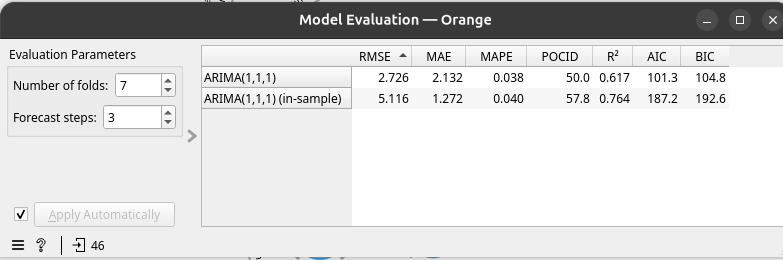

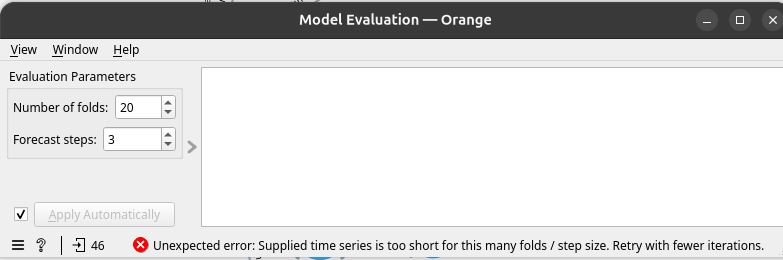

20 фолдів × 3: потрібно 61 точок, є 46
7 фолдів × 3: потрібно 22 точок, є 46
фолд 1: навчання 03.2014–09.2017 (43 міс.) → прогноз 10.2017–12.2017
фолд 2: навчання 03.2014–06.2017 (40 міс.) → прогноз 07.2017–09.2017
фолд 3: навчання 03.2014–03.2017 (37 міс.) → прогноз 04.2017–06.2017
фолд 4: навчання 03.2014–12.2016 (34 міс.) → прогноз 01.2017–03.2017
фолд 5: навчання 03.2014–09.2016 (31 міс.) → прогноз 10.2016–12.2016
фолд 6: навчання 03.2014–06.2016 (28 міс.) → прогноз 07.2016–09.2016
фолд 7: навчання 03.2014–03.2016 (25 міс.) → прогноз 04.2016–06.2016


In [ ]:
display(Image('ModelEval.png'), Image('WrongModelEval.png'))

max_lag = 1       
for folds in (20, 7):
    print(f'{folds} фолдів × {H}: потрібно {folds * H + max_lag} точок, є {len(y)}')

for k in range(1, N_FOLDS + 1):
    o = len(y) - k * H
    print(f'фолд {k}: навчання {y.index[0]:%m.%Y}–{y.index[o - 1]:%m.%Y} ({o} міс.) → прогноз {y.index[o]:%m.%Y}–{y.index[o + H - 1]:%m.%Y}')

**Висновок до завдання 13:**

1. **Model Evaluation** (7 фолдів × 3 кроки) — перший знімок:

   | | RMSE | MAE | MAPE | POCID | R² |
   |---|---|---|---|---|---|
   | ARIMA(1,1,1) | 2.726 | 2.132 | 0.038 | 50.0 | 0.617 |
   | ARIMA(1,1,1) (in-sample) | 5.116 | 1.272 | 0.040 | 57.8 | 0.764 |

2. **За типових налаштувань (20 × 3)** Orange видає: *«Supplied time series is too short for this many folds / step size. Retry with fewer iterations.»* Функція `model_evaluation` у `functions.py` перевіряє умову `n_folds · forecast_steps + max_lag > len(data)`, де `max_lag` = max(p, d, q) = 1. Для 20 × 3 потрібна 61 точка, а в ряді лише 46. Для 7 × 3 потрібно 22 точки. Найбільше допустимо (46 − 1) // 3 = 15 фолдів.
3. **Фолди Orange:** у фолді *k* модель навчається на `y[:-3k]` (завжди від 03.2014) і прогнозує наступні 3 місяці. Фолд 1 навчається до 09.2017 (43 міс.) і прогнозує 10–12.2017, а фолд 7 навчається до 03.2016 (25 міс.) і прогнозує 04–06.2016; повний перелік — у виводі коду. Це ті самі 7 відрізків, що й у завданнях 6–7, лише в зворотному порядку. Рядок «in-sample» — це модель, перевірена на тих самих даних, на яких вона навчалась, тому для оцінки прогнозу він не придатний.

## Завдання 14. Чому числа не збігаються

Порівняйте метрики Orange з метриками, які ви отримали в Частині 1 для **тієї самої** моделі
ARIMA(1,1,1) на **тих самих** 7 фолдах.

Для кожної з чотирьох метрик Orange — `RMSE`, `MAE`, `MAPE`, `POCID` — **відтворіть її значення в Python**,
тобто напишіть формулу, за якою Orange отримав саме це число, і переконайтеся, що ваш розрахунок
збігається з таблицею Orange до третього знака.

**У звіті наведіть:**
1. таблицю на чотири рядки: метрика · значення Orange · ваше відтворення в Python · формула;
2. **яка з метрик не відповідає своїй назві** — і чим саме вона відрізняється від того, що зазвичай позначають цією абревіатурою;
3. яка метрика збіглася між середовищами одразу і чому;
4. висновок: що саме треба перевіряти, перш ніж порівнювати числа з двох різних інструментів.

> 💡 **Підказка.** Жодна з розбіжностей не є помилкою Orange. Усі формули відкриті — шукайте їх у вихідному коді додатка Timeseries, файл `functions.py`.

In [ ]:
orange_order = [d for o in origins[::-1] for d in y.index[o:o + H]]
true_o = actual[orange_order].values
pred_o = arima_pred[orange_order].values
e = true_o - pred_o

pd.DataFrame({
    'Orange (ModelEval.png)': {'RMSE': 2.726, 'MAE': 2.132, 'MAPE': 0.038, 'POCID': 50.0},
    'відтворення в Python': {
        'RMSE':  np.sqrt(np.mean(e ** 2)),
        'MAE':   np.median(np.abs(e)),                       
        'MAPE':  np.mean(np.abs(e)) / np.mean(np.abs(true_o)), 
        'POCID': 100 * np.mean(np.diff(true_o) * np.diff(pred_o) > 0),
    },
    'звичне означення (завдання 7)': metrics(actual, arima_pred),
}).round(3)

,Orange (ModelEval.png),відтворення в Python,звичне означення (завдання 7)
RMSE,2.726,2.726,2.726
MAE,2.132,2.132,2.337
MAPE,0.038,0.038,3.744
POCID,50.000,50.000,NaN


**Висновок до завдання 14:**

1. **Відтворення метрик Orange** (ті самі 21 прогноз ARIMA(1,1,1), $e = y - \hat y$; формули з `functions.py`):

   | Метрика | Orange | Python | Формула Orange | Звичне означення (завд. 7) |
   |---|---|---|---|---|
   | RMSE | 2.726 | 2.726 | $\sqrt{\text{mean}(e^2)}$ | 2.726 |
   | MAE | 2.132 | 2.132 | $\text{median}\lvert e\rvert$ | 2.337 |
   | MAPE | 0.038 | 0.038 | $\text{mean}\lvert e\rvert \,/\, \text{mean}\lvert y\rvert$ (частка) | 3.744 % |
   | POCID | 50.0 | 50.0 | $100\cdot\text{mean}[\Delta y\cdot\Delta\hat y > 0]$ | — |

   Для POCID важливий порядок: Orange склеює фолди від кінця ряду і різниці рахує по цій склеєній послідовності.
2. **Не відповідає своїй назві MAE.** В Orange це **медіана** абсолютних похибок (так написано і в її документації: «Median absolute error»), а не середнє, як у scikit-learn і в Частині 1. Медіана нечутлива до кількох великих промахів, тому вона менша: 2.132 проти 2.337. **MAPE** теж нестандартна: це не середнє відсоткових похибок, а відношення середньої похибки до середнього рівня ряду, до того ж у частках, а не у відсотках.
3. **Одразу збіглась RMSE** (2.726). Формула в обох середовищах однакова, обидва рахують її по всіх 21 похибці разом, і від порядку фолдів вона не залежить. Отже, дані, фолди й модель однакові, і розбіжності пояснюються лише означеннями метрик.
4. **Перш ніж порівнювати числа з двох інструментів, треба перевірити:** формулу метрики (а не лише абревіатуру), однаковість вхідних даних, схему перевірки (фолди, горизонт, вікно), модель (порядок, константа) і спосіб агрегування похибок.

## Завдання 15. Матриця напрямку зміни

Метрика `POCID` у Orange вимірює, чи правильно модель передбачає **напрямок** зміни ціни.
Розгорніть її в таблицю 2×2: рядки — що сталося насправді (зросла / впала),
стовпці — що передбачила модель.

**У звіті наведіть:**
1. заповнену матрицю 2×2 для вашої моделі;
2. перевірку, що частка правильних передбачень збігається зі значенням POCID із Orange;
3. висновок: чи корисна ваша модель для рішення «купувати зараз чи чекати», і чому це **інше питання**, ніж те, на яке відповідають MAE та RMSE.

> 💡 **Підказка.** Ця матриця — часоворядовий відповідник матриці похибок із класифікації.

In [ ]:
fact      = pd.Series(np.where(np.diff(true_o) > 0, 'зросла', 'впала'), name='насправді')
predicted = pd.Series(np.where(np.diff(pred_o) > 0, 'зросте', 'впаде'), name='модель передбачила')
cm = pd.crosstab(fact, predicted)
display(cm)

correct = cm.loc['зросла', 'зросте'] + cm.loc['впала', 'впаде']
print(f'Правильний напрямок: {correct} із {cm.values.sum()} = {100 * correct / cm.values.sum():.1f} % (POCID в Orange = 50.0)')

модель передбачила,впаде,зросте
насправді,,
впала,5,5
зросла,5,5


Правильний напрямок: 10 із 20 = 50.0 % (POCID в Orange = 50.0)


**Висновок до завдання 15:**

1. **Матриця напрямку зміни** (20 пар сусідніх точок тієї самої склеєної послідовності, що й у POCID):

   | насправді \ модель передбачила | впаде | зросте |
   |---|---|---|
   | **впала** | 5 | 5 |
   | **зросла** | 5 | 5 |

2. Правильних передбачень 5 + 5 = 10 із 20, тобто **50.0 %**, що точно дорівнює POCID в Orange. Отже, POCID — це accuracy цієї матриці. При цьому 6 із 20 пар — стики між фолдами, а не справжні місячні зміни.
3. **Для рішення «купувати зараз чи чекати» модель некорисна:** напрямок зміни вона вгадує не краще за підкидання монети. Це **інше питання**, ніж те, на яке відповідають MAE і RMSE. Вони вимірюють, на скільки гривень прогноз відхиляється від факту, і не дивляться на знак зміни. Майже плаский прогноз ARIMA тримається близько до останнього рівня, тому має невелику MAE, але напрямку не передбачає. Матриця оцінює прогноз як класифікатор «вгору / вниз», а не як регресію.

---
# Загальний висновок

1. **Сезонність** у ряді слабка й ненадійна. $F_S = 0.48$ лише трохи перевищує поріг 0.3, сезонна складова STL щороку інша (розмах зростає з 2 до 6 грн), а класичне розкладання в Orange дає зовсім іншу її форму. На графіку змін стабільний лише березень. Ряд визначає тренд ($F_T = 0.99$): ціна зросла в 2.16 раза.
2. **Найкращим методом** виявився найпростіший базис «дрейф» (MAE 2.06 грн, MAPE 3.4 % на 7 фолдах × 3 кроки). ARIMA(1,1,1) йому програла (MAE 2.34) і майже не відрізнилась від наївного прогнозу, тож базис вона не перевершила. Випадковий поділ 75/25 занизив би помилку в ~1.3 раза.
3. **Точку зміни режиму** сканування знайшло в лютому 2015 (t = 13.5), але на рядах без зсуву такий самий результат виходить випадково (p = 0.57), тож це артефакт тренду. Зовнішнє пояснення (девальвація гривні) є, проте в ціні вона проявилась поступово, а не стрибком.
4. **Однаково названі метрики** в Orange і Python різні через різні означення: в Orange MAE — це медіана абсолютних похибок, MAPE — відношення середньої похибки до середнього рівня (частка), а POCID рахується по склеєних фолдах. Усі чотири метрики Orange відтворено в Python до третього знака, а однакова RMSE (2.726) підтверджує, що дані, фолди й модель однакові.
5. **Через лише 46 спостережень** не вдалося надійно встановити сезонність (3–4 значення на кожен місяць), відрізнити зміну режиму від тренду, однозначно обрати між ARIMA(0,1,1) і ARIMA(1,1,0), а оцінки метрик спираються лише на 21 тестовий прогноз.

---
# Критерії оцінювання

| Бали | Умова |
|---|---|
| **0** | Ряд не розкладено або прогноз не побудовано. Робота не зарахована. |
| **2** | Виконано лише Частину 1: ряд розкладено й прогноз побудовано, але в Orange аналіз не відтворено. |
| **3** | Виконано обидві частини, проте прогноз не зіставлено з наївним базисом, а розбіжність результатів двох середовищ не пояснено. |
| **4** | Ряд розкладено на складові; прогноз зіставлено з наївним базисом за ретроспективною перевіркою з рухомим початком; той самий аналіз відтворено в Orange; зіставлено результати двох середовищ і пояснено розбіжність метрик. |

**Знімаються бали за:**

* графіки без пояснення вибору геометрії та шкали;
* числа без письмового висновку;
* прогноз без порівняння з базисом;
* висновок «метрики різні, бо середовища різні» без відтворення формул;
* зошит, який не виконується від початку до кінця.

---
# Декларація про використання штучного інтелекту

Використання інструментів штучного інтелекту під час виконання цієї роботи **дозволено**.
Умова одна: ви маєте розуміти кожен рядок зданого коду й кожне написане твердження
і бути готовим пояснити їх на захисті.

Заповніть таблицю. Якщо ШІ не використовувався, напишіть «не використовувався» в першому рядку
й залиште решту порожньою.

| Питання | Ваша відповідь |
|---|---|
| Які інструменти використано (назва, версія) | Claude Opus 5.5|
| Для яких саме завдань | 1-10 |
| Що саме було згенеровано (код / текст / пояснення / виправлення помилок) | код |
| Що ви змінили у згенерованому результаті й чому | Замінила графік у 3 завданні на більш інтуїтивно зрозумілий, прибрала зайві обчислення |
| Що з отриманого ви **перевірили самостійно** і яким способом | |
| Чи траплялися у відповідях ШІ помилки; якщо так — які | |

**Підтверджую, що розумію весь зданий код і всі зроблені висновки
та можу пояснити будь-яку їх частину на захисті роботи.**

Підпис: Кшик  Дата: 27.10.2026